# Module 10 · Brownian motion and numerical stochastic dynamics
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **When does a stochastic time-step approximation preserve the variation, growth, and positivity of its model?**

Guided work: about 45–55 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 5, Part B (week 10)**. Combine it with Module 9 in **one submission due in week 10**. The sustained course project continues; there is no additional project.

[Course home](../index.html) · [Interactive lesson](../modules/module10.html) · [Project guide](../project-guide.html)

The Brownian and geometric Brownian paths are synthetic experiments. The final section tests a deliberately simple continuous positive proxy for observed daily bike-rental counts. Its assumptions are testable and its forecast comparison can be unfavorable.

## 1. Brownian increments scale with the square root of time
Standard Brownian motion has $W_0=0$, continuous paths, independent increments, and
$$W_{t+h}-W_t\sim N(0,h),\quad E[W_t]=0,\quad \operatorname{Var}(W_t)=t,\quad \operatorname{Cov}(W_s,W_t)=\min(s,t).$$
For a grid of $n$ steps over $T$, set $h=T/n$ and draw independent $Z_k\sim N(0,1)$:
$$\Delta W_k=\sqrt h Z_k,\qquad W_{k+1}=W_k+\Delta W_k.$$
These are exact Brownian values **on the grid**. Straight lines drawn between them are plotting interpolations; they do not reveal a continuous Brownian path or its between-grid extremes. Brownian paths are almost surely nowhere differentiable, despite being continuous.

Before running: if the time step is divided by four, how should the standard deviation of one increment change? What should happen to the endpoint variance at fixed $T$?

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import norm
from IPython.display import display
SEED, R, T = 6231, 4000, 1.0
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
def brownian_increments(n, replicas=R, horizon=T, seed=SEED):
    if n < 1 or replicas < 2 or horizon <= 0:
        raise ValueError("Use positive steps/horizon and at least two paths")
    return np.sqrt(horizon/n)*np.random.default_rng(seed).normal(size=(replicas, n))

def paths_from_increments(increments):
    return np.column_stack([np.zeros(len(increments)), np.cumsum(increments, axis=1)])

def mean_mcse(values):
    return np.mean(values), np.std(values, ddof=1)/np.sqrt(len(values))

In [3]:
n = 128
h = T/n
dw = brownian_increments(n)
w = paths_from_increments(dw)
time = np.linspace(0, T, n+1)
endpoint_mean, endpoint_mcse = mean_mcse(w[:, -1])
qv = np.sum(dw**2, axis=1)
qv_mean, qv_mcse = mean_mcse(qv)
assert np.array_equal(w[:, 0], np.zeros(R))
print("Endpoint mean and MCSE:", endpoint_mean, endpoint_mcse)
print("Endpoint sample variance; exact variance:", w[:, -1].var(ddof=1), T)
print("Cov(W_0.25,W_0.75); exact:", np.cov(w[:, 32], w[:, 96], ddof=1)[0, 1], 0.25)
print("Mean QV and MCSE; exact mean and variance:", qv_mean, qv_mcse, T, 2*T*T/n)

Endpoint mean and MCSE: -0.02139545784633562 0.0159272405664199
Endpoint sample variance; exact variance: 1.0147079682424465 1.0
Cov(W_0.25,W_0.75); exact: 0.2476439949009045 0.25
Mean QV and MCSE; exact mean and variance: 0.9995605919429174 0.001974607701972558 1.0 0.015625


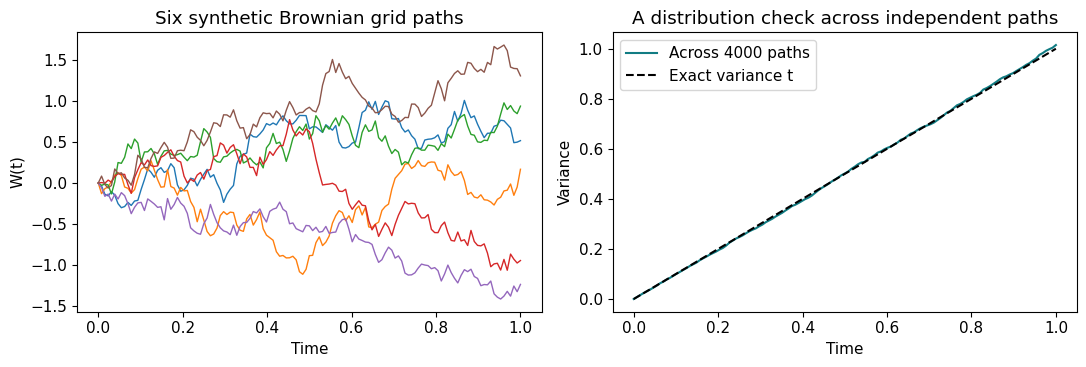

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for path in w[:6]:
    axes[0].plot(time, path, linewidth=1)
axes[0].set(xlabel="Time", ylabel="W(t)", title="Six synthetic Brownian grid paths")
axes[1].plot(time, w.var(axis=0, ddof=1), color="#117c83", label="Across 4000 paths")
axes[1].plot(time, time, "k--", label="Exact variance t")
axes[1].set(xlabel="Time", ylabel="Variance", title="A distribution check across independent paths")
axes[1].legend(); fig.tight_layout(); plt.show()

## 2. Quadratic variation catches a scaling error
On an equal grid, quadratic variation is $Q_n=\sum_{k=1}^n(\Delta W_k)^2$. For independent Brownian increments,
$$E[Q_n]=T,\qquad \operatorname{Var}(Q_n)=2T^2/n.$$
Thus $Q_n\to T$ in mean square; variation does not disappear as the grid is refined. A single realized $Q_n$ is random. Estimate its expectation across independent paths and report the Monte Carlo standard error (MCSE).

The deliberately wrong increments $hZ_k$ have variance $h^2$, so their endpoint variance and expected quadratic variation are both $nh^2=Th$. Their plots shrink toward a constant as $h\to0$; smoother appearance is evidence of the wrong limit, not greater accuracy.

In [5]:
scaling_rows = []
for steps in [8, 32, 128, 512]:
    correct = brownian_increments(steps, seed=SEED+17)
    for label, increments in [("sqrt(h) Z", correct), ("WRONG h Z", correct*np.sqrt(T/steps))]:
        endpoint = increments.sum(axis=1)
        variation = np.sum(increments**2, axis=1)
        avg, se = mean_mcse(variation)
        expected = T if label == "sqrt(h) Z" else T*T/steps
        scaling_rows.append(dict(n=steps, construction=label, endpoint_variance=endpoint.var(ddof=1),
            QV_mean=avg, QV_MCSE=se, exact_variance_and_QV=expected))
scaling = pd.DataFrame(scaling_rows)
display(scaling)

,n,construction,endpoint_variance,QV_mean,QV_MCSE,exact_variance_and_QV
0,8,sqrt(h) Z,1.003522,1.004499,0.008049,1.000000
1,8,WRONG h Z,0.125440,0.125562,0.001006,0.125000
2,32,sqrt(h) Z,0.995280,0.996721,0.003975,1.000000
3,32,WRONG h Z,0.031102,0.031148,0.000124,0.031250
4,128,sqrt(h) Z,1.008560,0.996975,0.001954,1.000000
5,128,WRONG h Z,0.007879,0.007789,0.000015,0.007812
6,512,sqrt(h) Z,0.985303,0.998680,0.000982,1.000000
7,512,WRONG h Z,0.001924,0.001951,0.000002,0.001953


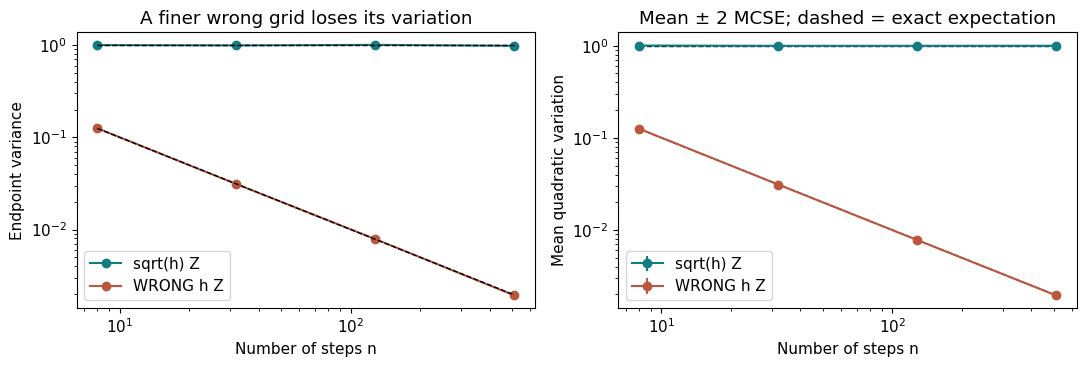

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, color in [("sqrt(h) Z", "#117c83"), ("WRONG h Z", "#bb573d")]:
    block = scaling[scaling.construction == label]
    axes[0].loglog(block.n, block.endpoint_variance, "o-", color=color, label=label)
    axes[1].errorbar(block.n, block.QV_mean, yerr=2*block.QV_MCSE, fmt="o-", color=color, label=label)
    for ax in axes:
        ax.plot(block.n, block.exact_variance_and_QV, "k--", linewidth=1)
        ax.set(xscale="log", yscale="log", xlabel="Number of steps n")
axes[0].set(ylabel="Endpoint variance", title="A finer wrong grid loses its variation")
axes[1].set(ylabel="Mean quadratic variation", title="Mean ± 2 MCSE; dashed = exact expectation")
axes[0].legend(); axes[1].legend(); fig.tight_layout(); plt.show()

## 3. Geometric Brownian motion: specify the drift convention
For an **Itô** stochastic differential equation (SDE),
$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t,\quad S_0>0,$$
the exact solution is
$$S_t=S_0\exp\{(\mu-\tfrac12\sigma^2)t+\sigma W_t\}.$$
Itô's formula gives $d\log S_t=(\mu-\sigma^2/2)dt+\sigma dW_t$: the correction matters. If a source instead writes $S_t=S_0e^{mt+\sigma W_t}$, its **log drift** is $m=\mu-\sigma^2/2$, not the SDE drift $\mu$.

$$E[S_T]=S_0e^{\mu T},\qquad \operatorname{Var}(S_T)=S_0^2e^{2\mu T}(e^{\sigma^2T}-1),\qquad
\operatorname{median}(S_T)=S_0e^{(\mu-\sigma^2/2)T}.$$
At $S_0=1,\mu=0.2,\sigma=0.8,T=1$, the exact mean is 1.221403, variance 1.337392, and median 0.886920. The pointwise median can decline while the mean rises because the distribution is right-skewed. These are model quantities, not investment claims.

Euler–Maruyama uses $S^E_{k+1}=S^E_k(1+\mu h+\sigma\Delta W_k)$. Compare exact and Euler values using **the same increments**. An exact lognormal update is available for GBM; Euler is studied here as a numerical method for SDEs whose exact updates may be unavailable.

In [7]:
def coupled_gbm(increments, mu=0.2, sigma=0.8, s0=1.0, horizon=T):
    if sigma < 0 or s0 <= 0 or horizon <= 0:
        raise ValueError("Use sigma >= 0, s0 > 0, and horizon > 0")
    n = increments.shape[1]
    time = np.linspace(0, horizon, n+1)
    brownian = paths_from_increments(increments)
    exact = s0*np.exp((mu-0.5*sigma**2)*time + sigma*brownian)
    factors = 1 + mu*horizon/n + sigma*increments
    euler = s0*np.column_stack([np.ones(len(increments)), np.cumprod(factors, axis=1)])
    return time, exact, euler

def coarsen(increments, n):
    if increments.shape[1] % n:
        raise ValueError("The coarse grid must divide the fine grid")
    return increments.reshape(len(increments), n, -1).sum(axis=2)

In [8]:
def gbm_moments(mu=0.2, sigma=0.8, s0=1., horizon=T):
    mean = s0*np.exp(mu*horizon)
    variance = s0**2*np.exp(2*mu*horizon)*np.expm1(sigma**2*horizon)
    return mean, variance, s0*np.exp((mu-0.5*sigma**2)*horizon)

def euler_mean_bias(n, mu=0.2, s0=1., horizon=T):
    return s0*((1+mu*horizon/n)**n-np.exp(mu*horizon))

def exact_strong_rms(n, mu=0.2, sigma=0.8, s0=1., horizon=T):
    h = horizon/n
    exact_second = np.exp((2*mu+sigma**2)*horizon)
    euler_second = ((1+mu*h)**2 + sigma**2*h)**n
    cross = np.exp(mu*horizon)*(1+(mu+sigma**2)*h)**n
    return s0*np.sqrt(np.maximum(0., exact_second+euler_second-2*cross))

In [9]:
fine_dw = brownian_increments(256, seed=SEED+1)
time_g, exact_g, euler_g = coupled_gbm(coarsen(fine_dw, 128))
exact_mean, exact_var, exact_median = gbm_moments()
assert np.allclose([exact_mean, exact_var, exact_median], [1.22140275816017, 1.33739231671029, 0.88692043671716])
summary_rows = []
for label, values in [("Exact GBM grid", exact_g[:, -1]), ("Euler, n=128", euler_g[:, -1])]:
    avg, se = mean_mcse(values)
    summary_rows.append(dict(method=label, mean=avg, mean_MCSE=se,
        variance=values.var(ddof=1), median=np.median(values)))
display(pd.DataFrame(summary_rows))
print("Exact model mean, variance, median:", gbm_moments())
assert np.all(exact_g > 0)

,method,mean,mean_MCSE,variance,median
0,Exact GBM grid,1.232099,0.018442,1.360390,0.885995
1,"Euler, n=128",1.232531,0.018460,1.363025,0.890113


Exact model mean, variance, median: (1.2214027581601699, 1.3373923167102895, 0.8869204367171575)


In [10]:
stress_time, stress_exact, stress_euler = coupled_gbm(coarsen(fine_dw, 4), sigma=2.)
ever_nonpositive = np.any(stress_euler <= 0, axis=1)
terminal_negative = stress_euler[:, -1] < 0
p_factor_negative = norm.cdf(-(1+0.2/4)/(2*np.sqrt(1/4)))
p_ever = 1-(1-p_factor_negative)**4
p_terminal = (1-(1-2*p_factor_negative)**4)/2
assert np.allclose([p_ever, p_terminal], [0.4702351495, 0.3755822682])
print("Stress: fraction ever nonpositive; exact probability:", ever_nonpositive.mean(), p_ever)
print("Stress: fraction terminal negative; exact probability:", terminal_negative.mean(), p_terminal)
visible_crossing = (stress_euler.min(axis=1) < -0.3) & (stress_exact.max(axis=1) < 5)
stress_index = int(np.flatnonzero(visible_crossing)[0])
assert np.all(stress_exact > 0) and terminal_negative.sum() <= ever_nonpositive.sum()

Stress: fraction ever nonpositive; exact probability: 0.47275 0.4702351494751493
Stress: fraction terminal negative; exact probability: 0.37825 0.37558226821611046


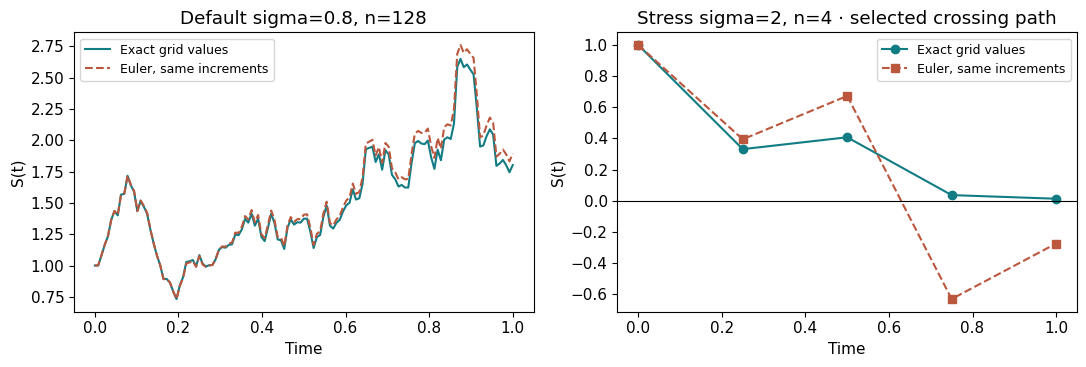

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(time_g, exact_g[0], color="#117c83", label="Exact grid values")
axes[0].plot(time_g, euler_g[0], "--", color="#bb573d", label="Euler, same increments")
axes[0].set(xlabel="Time", ylabel="S(t)", title="Default sigma=0.8, n=128")
axes[1].plot(stress_time, stress_exact[stress_index], "o-", color="#117c83", label="Exact grid values")
axes[1].plot(stress_time, stress_euler[stress_index], "s--", color="#bb573d", label="Euler, same increments")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Time", ylabel="S(t)", title="Stress sigma=2, n=4 · selected crossing path")
for ax in axes: ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

Exact GBM is strictly positive, but a Gaussian Euler factor can be negative. A negative factor flips the sign; two flips can restore a positive terminal value. Consequently **ever nonpositive** differs from **terminal negative**. Exact zeros have probability zero under this model, although finite arithmetic can behave differently in extreme regimes. The stress panel intentionally selects a clearly visible sign failure (Euler minimum below −0.3 and exact maximum below 5); the all-path proportions above quantify frequency without selection.

Never silently clip negative Euler values to zero: that defines a different scheme and changes its distribution. Refine the step and check errors, or use the exact GBM update when this model is appropriate. Positivity alone does not establish an accurate simulation.

## 4. Couple grids and separate two kinds of error
Create fine-grid Brownian increments once and sum adjacent increments to obtain each coarser grid. This preserves both the required Gaussian increment laws and a common underlying Brownian driver. For terminal error $e_r=S_T^{E,(r)}-S_T^{(r)}$, compute
$$\widehat{\mathrm{RMSE}}=\sqrt{R^{-1}\sum_r e_r^2},\qquad
\widehat b=R^{-1}\sum_r e_r,\qquad \operatorname{MCSE}(\widehat b)=s(e_1,\ldots,e_R)/\sqrt R.$$
The first measures **strong pathwise error at the terminal time**; the second estimates the weak error for the mean functional $f(S)=S$. General weak error concerns $E[f(S_T^E)]-E[f(S_T)]$, not only the mean. Do not compute paired-error MCSE by pretending the exact and Euler samples are independent.

For this model, independent increments give the exact finite-step Euler mean:
$$E[S_n^E]=S_0(1+\mu h)^n,\qquad b_n=S_0\{(1+\mu h)^n-e^{\mu T}\}.$$
A noisy mean-error estimate can obscure this small bias. MCSE measures sampling error; refining $h$ reduces discretization error but does not by itself remove Monte Carlo uncertainty. Under standard regularity and moment conditions, Euler–Maruyama has strong order $1/2$ and weak order 1 for suitable sufficiently smooth test functions. GBM satisfies the relevant conditions here; no finite plot or one fitted slope proves those asymptotic claims for arbitrary SDEs.

In [12]:
def refinement_table(seed=SEED+1, replicas=R):
    fine = brownian_increments(256, replicas=replicas, seed=seed)
    rows = []
    for n in [4, 16, 64, 256]:
        _, exact, euler = coupled_gbm(coarsen(fine, n))
        error = euler[:, -1]-exact[:, -1]
        avg, se = mean_mcse(error)
        rows.append(dict(n=n, h=T/n, terminal_RMSE=np.sqrt(np.mean(error**2)),
            exact_RMS=exact_strong_rms(n), paired_mean_error=avg,
            paired_MCSE=se, exact_mean_bias=euler_mean_bias(n)))
    return pd.DataFrame(rows)

In [13]:
refinement = refinement_table()
display(refinement)
assert np.allclose(refinement.exact_RMS, [0.3652171660, 0.1884715739, 0.0949268411, 0.0475472494])
assert np.all(refinement.exact_mean_bias < 0)
print("Rows reuse a common fine-grid driver; row errors are not independent of one another.")

,n,h,terminal_RMSE,exact_RMS,paired_mean_error,paired_MCSE,exact_mean_bias
0,4,0.250000,0.364117,0.365217,-0.013421,0.005754,-0.005897
1,16,0.062500,0.170705,0.188472,0.000997,0.002699,-0.001513
2,64,0.015625,0.090120,0.094927,0.001510,0.001425,-0.000381
3,256,0.003906,0.045911,0.047547,0.000049,0.000726,-0.000095


Rows reuse a common fine-grid driver; row errors are not independent of one another.


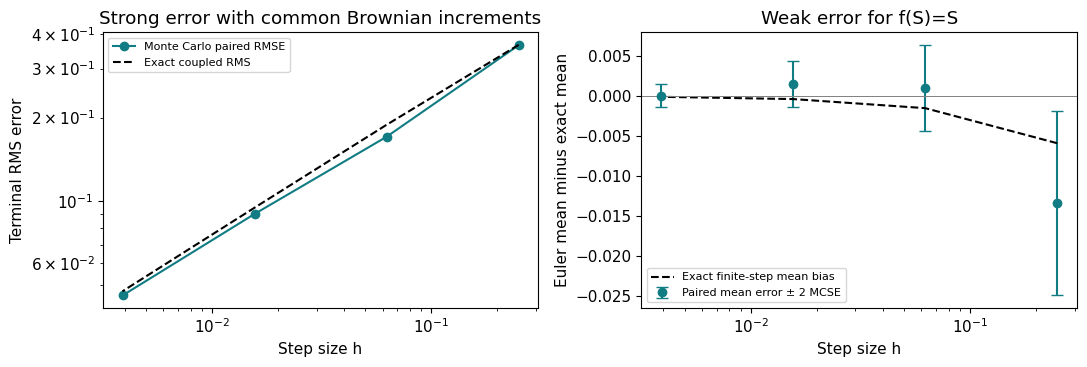

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].loglog(refinement.h, refinement.terminal_RMSE, "o-", color="#117c83", label="Monte Carlo paired RMSE")
axes[0].loglog(refinement.h, refinement.exact_RMS, "k--", label="Exact coupled RMS")
axes[0].set(xlabel="Step size h", ylabel="Terminal RMS error", title="Strong error with common Brownian increments")
axes[1].errorbar(refinement.h, refinement.paired_mean_error, yerr=2*refinement.paired_MCSE,
                 fmt="o", capsize=4, color="#117c83", label="Paired mean error ± 2 MCSE")
axes[1].plot(refinement.h, refinement.exact_mean_bias, "k--", label="Exact finite-step mean bias")
axes[1].axhline(0, color="gray", linewidth=0.7)
axes[1].set(xscale="log", xlabel="Step size h", ylabel="Euler mean minus exact mean", title="Weak error for f(S)=S")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

The independent strong-error benchmark above follows from
$$E[(S_T^E-S_T)^2]=S_0^2\left[e^{(2\mu+\sigma^2)T}+\{(1+\mu h)^2+\sigma^2h\}^n-2e^{\mu T}\{1+(\mu+\sigma^2)h\}^n\right].$$
It compares this Euler scheme with exact GBM driven by the same Brownian motion. If independently generated paths were subtracted, their nonzero process variability would remain even as $h\to0$. Independent simulations can estimate a difference of expectations, but their squared path differences are not the strong discretization error intended here.

## 5. Can a diffusion proxy predict daily bike counts?
The unchanged UCI Bike Sharing sample contains **365 observed system-wide daily completed-rental totals in 2011**: Fanaee-T (2013), [UCI Bike Sharing](https://doi.org/10.24432/C5W894), CC BY 4.0. Counts are discrete and aggregate a whole day. They are not continuous demand trajectories, individual arrivals, station inventories, or unserved demand.

All local counts are positive. We can therefore explore, rather than presume, a continuous positive GBM proxy at daily grid points. No pseudocount is added. With one day as the time unit, training log changes $r_d=\log C_d-\log C_{d-1}$ would be iid $N(m,v)$ under this proxy. Fit **only the 242 within-training increments from January–August**:
$$\widehat m=\overline r,\quad \widehat v=242^{-1}\sum(r_d-\overline r)^2,\quad
\widehat\sigma=\sqrt{\widehat v},\quad \widehat\mu=\widehat m+\widehat v/2.$$
These are Gaussian iid maximum-likelihood formulas; their model-based interpretation depends on the assumptions. In general, for spacing $\Delta$, divide the increment mean and variance by $\Delta$ before identifying drift and diffusion variance per unit time.

In [15]:
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(p for p in candidates if (p/"data/bike_daily_2011.csv").is_file())
data_path = ROOT/"data/bike_daily_2011.csv"
source = json.loads((ROOT/"data/source_metadata.json").read_text())
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(data_path, parse_dates=["dteday"])
assert bike.dteday.tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
assert len(bike) == 365 and bike.dteday.is_unique and bike.cnt.gt(0).all()
training = bike[bike.dteday < "2011-09-01"]
later = bike[bike.dteday >= "2011-09-01"]
assert len(training) == 243 and len(later) == 122
assert training.cnt.sum() == 802684 and later.cnt.sum() == 440419
print("365 positive daily counts; 243 training days, 122 development forecast targets.")

365 positive daily counts; 243 training days, 122 development forecast targets.


In [16]:
log_increments = np.diff(np.log(training.cnt.to_numpy(float)))
m_hat = log_increments.mean()
v_hat = log_increments.var(ddof=0)  # Gaussian iid maximum-likelihood convention.
sigma_hat, mu_hat = np.sqrt(v_hat), m_hat+0.5*v_hat
lag1 = np.corrcoef(log_increments[:-1], log_increments[1:])[0, 1]
assert len(log_increments) == 242
fit_table = pd.DataFrame([dict(increments=len(log_increments), m_per_day=m_hat,
    variance_per_day=v_hat, sigma_per_sqrt_day=sigma_hat,
    mu_per_day=mu_hat, lag1_correlation=lag1)])
display(fit_table)
assert np.allclose([m_hat, v_hat], [0.006760680934123231, 0.11779139973417223])

,increments,m_per_day,variance_per_day,sigma_per_sqrt_day,mu_per_day,lag1_correlation
0,242,0.006761,0.117791,0.343208,0.065656,-0.379502


### Frozen parameters, rolling one-day forecasts
For each September–December target day $d$, use the actually observed previous count $C_{d-1}$ with the parameters frozen above. The first forecast uses August 31. Under the candidate model,
$$\widehat E[C_d\mid C_{d-1}]=C_{d-1}e^{\widehat\mu},\quad
\widehat{\mathrm{median}}(C_d\mid C_{d-1})=C_{d-1}e^{\widehat m},$$
and a central 80% conditional interval is $C_{d-1}\exp\{\widehat m\pm z_{0.9}\widehat\sigma\}$, where $z_{0.9}\approx1.28155$. This band conditions on fitted parameters, ignores parameter uncertainty, and has no empirical coverage guarantee under misspecification. Its real-valued limits belong to a continuous proxy for counts.

Compare the **conditional mean** with persistence $\widehat C_d=C_{d-1}$ on exactly the same 122 targets, using RMSE and MAE. A conditional median minimizes absolute loss under the fitted model, whereas a conditional mean minimizes squared loss; reporting MAE for the mean remains a valid descriptive comparison. These are rolling one-day forecasts, not a recursive multi-day forecast issued once on August 31. Earlier modules have already inspected September–December; it is a reused development comparison, not a fresh final test.

In [17]:
forecast = bike.assign(previous=bike.cnt.shift(1)).loc[bike.dteday >= "2011-09-01"].copy()
forecast["mean"] = forecast.previous*np.exp(mu_hat)
forecast["median"] = forecast.previous*np.exp(m_hat)
z80 = norm.ppf(0.9)
forecast["lower"] = forecast.previous*np.exp(m_hat-z80*sigma_hat)
forecast["upper"] = forecast.previous*np.exp(m_hat+z80*sigma_hat)
forecast["covered"] = forecast.cnt.between(forecast.lower, forecast.upper)
assert len(forecast) == 122 and forecast.previous.notna().all()
assert forecast.iloc[0].previous == training.iloc[-1].cnt
score_rows = []
for label, estimate in [("GBM conditional mean", forecast["mean"]), ("Persistence", forecast.previous)]:
    error = estimate-forecast.cnt
    score_rows.append(dict(model=label, targets=len(error), RMSE=np.sqrt(np.mean(error**2)), MAE=np.mean(abs(error))))
scores = pd.DataFrame(score_rows)
display(scores)
print("Central 80% conditional interval:", int(forecast.covered.sum()), "/", len(forecast), "=", forecast.covered.mean())

,model,targets,RMSE,MAE
0,GBM conditional mean,122,1052.476584,756.941113
1,Persistence,122,982.418265,697.418033


Central 80% conditional interval: 102 / 122 = 0.8360655737704918


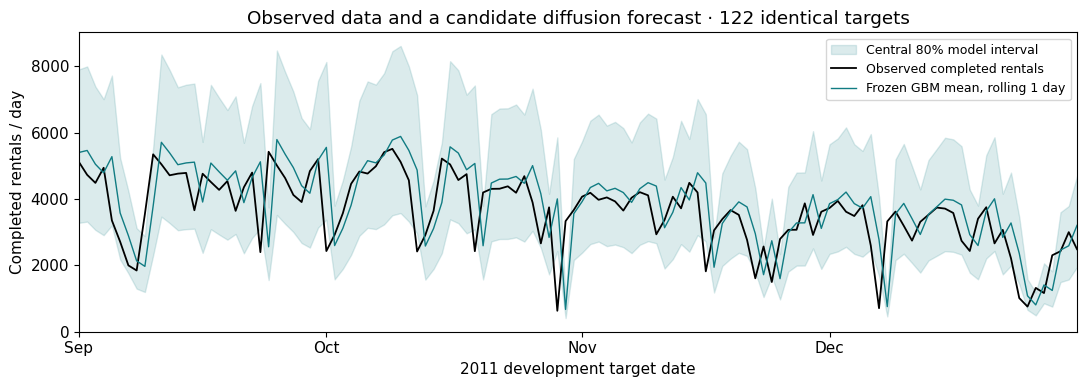

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
dates = forecast.dteday.to_numpy()
ax.fill_between(dates, forecast.lower.to_numpy(), forecast.upper.to_numpy(), color="#117c83", alpha=0.15, label="Central 80% model interval")
ax.plot(dates, forecast.cnt.to_numpy(), color="black", linewidth=1.3, label="Observed completed rentals")
ax.plot(dates, forecast["mean"].to_numpy(), color="#117c83", linewidth=1, label="Frozen GBM mean, rolling 1 day")
ax.set(xlabel="2011 development target date", ylabel="Completed rentals / day", title="Observed data and a candidate diffusion forecast · 122 identical targets")
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(dates[0], dates[-1])
ax.legend(fontsize=9, loc="upper right"); fig.tight_layout(); plt.show()

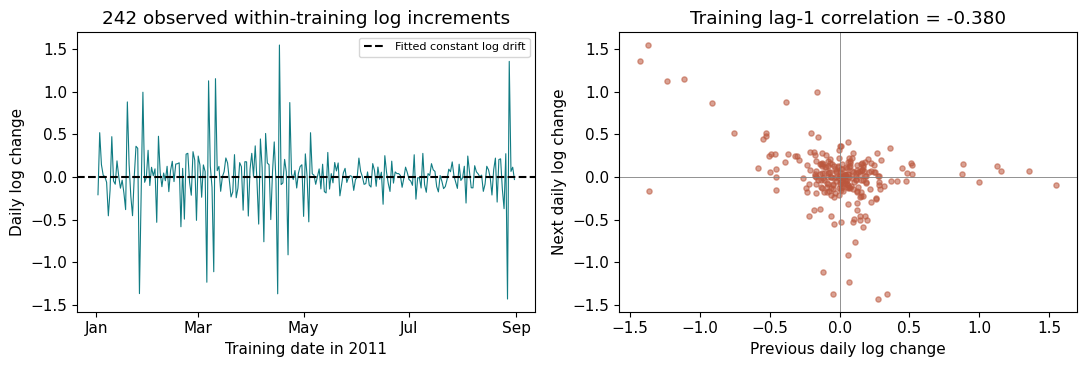

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(training.dteday.iloc[1:], log_increments, color="#117c83", linewidth=0.8)
axes[0].axhline(m_hat, color="black", linestyle="--", label="Fitted constant log drift")
axes[0].set(xlabel="Training date in 2011", ylabel="Daily log change", title="242 observed within-training log increments")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b")); axes[0].legend(fontsize=8)
axes[1].scatter(log_increments[:-1], log_increments[1:], s=14, alpha=0.55, color="#bb573d")
axes[1].axhline(0, color="gray", linewidth=0.6); axes[1].axvline(0, color="gray", linewidth=0.6)
axes[1].set(xlabel="Previous daily log change", ylabel="Next daily log change", title=f"Training lag-1 correlation = {lag1:.3f}")
fig.tight_layout(); plt.show()

The reproduced mean-forecast RMSE/MAE are approximately **1052.48/756.94**, versus **982.42/697.42** for persistence. Coverage is **102/122 = 83.6%** for the nominal 80% band. Coverage close to the nominal percentage does not validate the entire distribution or the diffusion mechanism. No interval is built from future observations.

The training lag-1 log-increment correlation is approximately **−0.380**, evidence against independent increments. Weather, weekday patterns, seasonality, temporary disruptions, discrete totals, and a changing scale all challenge constant-coefficient GBM. Positive support is useful but insufficient. A rolling forecast can benefit from observing each preceding day even when a fixed-origin GBM extrapolation would grow implausibly. Do not reinterpret a grid-point proxy as an observed intraday stochastic process.

## 6. Verify claims, including optional AI suggestions
An optional AI assistant proposes these four lines. Identify the mathematical or data error, repair it, and verify your correction locally. The activity works without an AI account or a paid API.

```python
dW = dt * rng.normal()
exact = S0 * np.exp(mu*T + sigma*W_T)
error = euler(seed=1) - exact_gbm(seed=2)
fit = np.diff(np.log(all_365_counts))
```

Use two independent forms of evidence, such as exact distribution/moment calculations, paired numerical comparisons, a step-refinement experiment, or a date/checksum audit. Preserve prompts and accepted corrections if AI is used. A confident explanation or an attractive path plot is not a verification.

In [20]:
assert np.allclose(gbm_moments(sigma=0)[1], 0)
assert np.allclose(coarsen(fine_dw, 4).sum(axis=1), fine_dw.sum(axis=1))
assert np.allclose(refinement.exact_mean_bias, (1+0.2/refinement.n)**refinement.n-np.exp(0.2))
assert forecast.covered.sum() == 102
assert np.allclose(scores.RMSE, [1052.47658, 982.41827])
assert np.allclose(scores.MAE, [756.94111, 697.41803])
assert forecast.dteday.min() == pd.Timestamp("2011-09-01")
print("PASS: exact moments, nested-grid coupling, finite-step bias, and chronological data checks")
print("Runtime:", platform.python_version(), {p: metadata.version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]})

PASS: exact moments, nested-grid coupling, finite-step bias, and chronological data checks


Runtime: 3.10.9 {'numpy': '1.24.2', 'pandas': '2.0.0', 'scipy': '1.10.1', 'matplotlib': '3.7.1'}


## 7. Four investigations · your work
Keep the following cells unanswered in the distributed notebook. Submit your calculations, interpretation, and verification with Module 9 as one Concept Lab 5 submission due in week 10. The worked examples above are templates, not substitutes for the requested comparisons.

### E1 — Check Brownian scaling
At T=1 and R=4000 independent paths, compare n=16, 64, and 256 using increments sqrt(h)*Z and the deliberately wrong h*Z. Report endpoint variance and mean quadratic variation, with the exact values each construction predicts. Explain why a smoother plot is not evidence of a better Brownian approximation.

In [21]:
# YOUR WORK — E1
# Add your calculation and a short interpretation here.

### E2 — Compare exact GBM and Euler
With S0=1, mu=0.2, sigma=0.8, and T=1, reproduce the exact terminal mean, variance, and median and compare a coupled Euler simulation. Then set sigma=2 and n=4; report the proportion of paths ever nonpositive and the proportion with a negative terminal value. Explain why these events differ and why clipping negative values changes the scheme.

In [22]:
# YOUR WORK — E2
# Add your calculation and a short interpretation here.

### E3 — Separate discretization and Monte Carlo error
Use R=4000 paths and nested n=4, 16, 64, and 256 steps with the same Brownian increments for each exact/Euler pair. Report terminal root-mean-square error and paired mean error with its MCSE; compare the latter with the exact finite-step mean bias. Repeat with a second seed. Explain why independently simulated exact and Euler paths cannot estimate strong pathwise error, and why one finite convergence plot does not prove an asymptotic order.

In [23]:
# YOUR WORK — E3
# Add your calculation and a short interpretation here.

### E4 — Audit a bike-demand diffusion proxy
Fit log-increment parameters using only January–August. Make frozen-parameter rolling one-day forecasts for all 122 September–December dates, using the observed preceding day; compare mean-forecast RMSE and MAE with persistence on the same dates and report central 80% interval coverage. Inspect training log-increment dependence and explain the difference from fixed-origin multi-day prediction. State the data and model limitations, repair the four flawed verification lines using two independent checks, and disclose any optional AI assistance.

In [24]:
# YOUR WORK — E4
# Add your calculation and a short interpretation here.

## 8. Optional extension and next step
Add a deterministic seasonal log-drift term fitted only on the training interval, then compare it with persistence using the same target dates and explicitly chosen loss. Or implement Milstein for GBM, adding `0.5*sigma**2*S*(dW**2-h)` to Euler, and assess its coupled error. State the additional assumptions; do not infer an order from a single noisy slope.

Continue to [Module 11](../modules/module11.html) for Gaussian processes, covariance kernels, and prediction uncertainty. The sustained course project receives the same model audit and numerical verification evidence, without introducing another project.

Reading: D. J. Higham (2001), [An Algorithmic Introduction to Numerical Simulation of Stochastic Differential Equations](https://doi.org/10.1137/S0036144500378302). All calculations here run offline with the supplied data and installed course packages.